In [ ]:
# P2: Fintech Transaction Fraud Scoring
# Environment setup

import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Environment ready!")

Python: 3.13.16
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1
Environment ready!


In [ ]:
import numpy as np
import pandas as pd

np.random.seed(42)
n = 10000

amount = np.random.lognormal(mean=6.5, sigma=1.0, size=n).round(2)
location_delta_km = np.random.exponential(scale=20, size=n).round(2)
device_id = np.random.choice(
    ["DEV_A", "DEV_B", "DEV_C", "DEV_D", "DEV_E"],
    size=n
)
transactions_last_hour = np.random.poisson(lam=2, size=n)
customer_age = np.random.randint(18, 76, size=n)
account_age_days = np.random.randint(1, 3650, size=n)

# Synthetic risk score used only to create demonstration labels.
risk_score = (
    0.9 * (amount > 1000)
    + 1.1 * (location_delta_km > 50)
    + 1.2 * (transactions_last_hour >= 5)
    + 0.8 * (account_age_days < 30)
    + 0.6 * (customer_age < 23)
    + np.random.normal(0, 0.8, size=n)
)

fraud_probability = 1 / (1 + np.exp(-(risk_score - 2.5)))
is_fraud = np.random.binomial(1, fraud_probability)

transactions = pd.DataFrame({
    "transaction_id": [f"TXN{i:06d}" for i in range(1, n + 1)],
    "customer_id": np.random.randint(1000, 3000, size=n),
    "amount": amount,
    "location_delta_km": location_delta_km,
    "device_id": device_id,
    "transactions_last_hour": transactions_last_hour,
    "customer_age": customer_age,
    "account_age_days": account_age_days,
    "is_fraud": is_fraud
})

transactions.to_csv("p2_transactions_synthetic.csv", index=False)

print("Dataset shape:", transactions.shape)
print("\nFirst five rows:")
display(transactions.head())

print("\nFraud label distribution:")
display(
    transactions["is_fraud"]
    .value_counts()
    .rename(index={0: "Legitimate", 1: "Fraud"})
    .to_frame("count")
)

print("\nMissing values:", transactions.isna().sum().sum())
print("\nSaved: p2_transactions_synthetic.csv")

Dataset shape: (10000, 9)

First five rows:


,transaction_id,customer_id,amount,location_delta_km,device_id,transactions_last_hour,customer_age,account_age_days,is_fraud
0,TXN000001,2304,1093.04,7.75,DEV_C,2,30,1451,1
1,TXN000002,1306,579.25,2.17,DEV_E,2,75,61,0
2,TXN000003,2678,1271.16,1.49,DEV_C,2,72,1733,0
3,TXN000004,2357,3050.41,1.98,DEV_C,0,32,2960,1
4,TXN000005,1012,526.29,17.49,DEV_B,1,43,92,0



Fraud label distribution:


,count
is_fraud,
Legitimate,8373
Fraud,1627



Missing values: 0

Saved: p2_transactions_synthetic.csv


In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Verify the dataset exists
print("Dataset shape:", transactions.shape)
print("Columns:", transactions.columns.tolist())

# Separate features and target
X = transactions.drop(
    columns=["transaction_id", "customer_id", "is_fraud"]
)
y = transactions["is_fraud"]

# Encode device IDs
X = pd.get_dummies(
    X,
    columns=["device_id"],
    dtype=int
)

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Dataset shape: (10000, 9)
Columns: ['transaction_id', 'customer_id', 'amount', 'location_delta_km', 'device_id', 'transactions_last_hour', 'customer_age', 'account_age_days', 'is_fraud']

Training features: (8000, 10)
Testing features: (2000, 10)
Training labels: (8000,)
Testing labels: (2000,)



===== Decision Tree =====
              precision    recall  f1-score   support

  Legitimate       0.87      0.69      0.77      1675
       Fraud       0.22      0.45      0.30       325

    accuracy                           0.65      2000
   macro avg       0.54      0.57      0.53      2000
weighted avg       0.76      0.65      0.69      2000


===== Random Forest =====
              precision    recall  f1-score   support

  Legitimate       0.86      0.84      0.85      1675
       Fraud       0.25      0.27      0.26       325

    accuracy                           0.75      2000
   macro avg       0.55      0.56      0.55      2000
weighted avg       0.76      0.75      0.75      2000



,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Decision Tree,0.6500,0.2197,0.4523,0.2958,0.5751
Random Forest,0.7485,0.2486,0.2708,0.2592,0.6161


Saved: p2_fraud_classification_comparison.csv


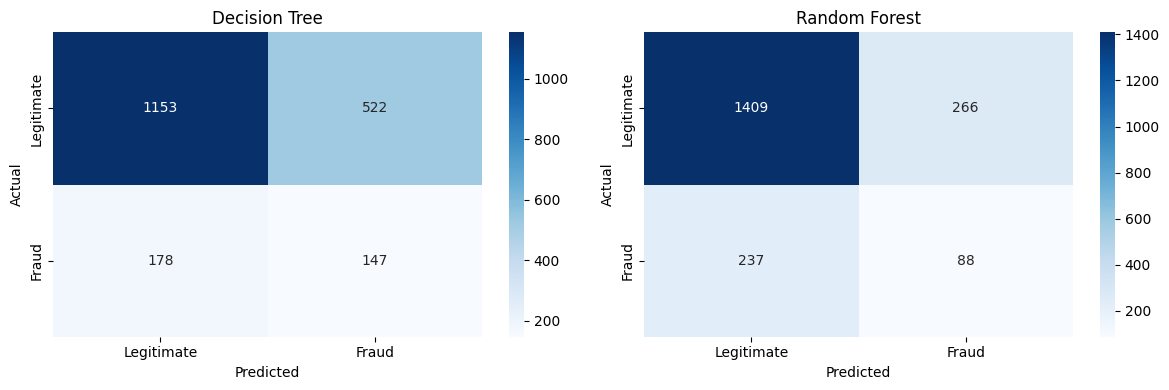

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define the two models
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    print(f"\n===== {name} =====")
    print(classification_report(
        y_test, predictions,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    ))

comparison = pd.DataFrame(results).set_index("Model")
display(comparison.round(4))

# Save the required comparison matrix
comparison.to_csv("p2_fraud_classification_comparison.csv")
print("Saved: p2_fraud_classification_comparison.csv")

# Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, model) in zip(axes, trained_models.items()):
    predictions = model.predict(X_test)
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"],
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Check that the source dataset exists
if "transactions" not in globals():
    raise NameError(
        "transactions is missing. Rerun the dataset-generation cell first."
    )

# Clean the dataset
transactions = transactions.drop_duplicates()
transactions = transactions.dropna(subset=["is_fraud"]).copy()

# Separate features and target
X = transactions.drop(
    columns=["transaction_id", "customer_id", "is_fraud"]
)
y = transactions["is_fraud"].astype(int)

# Encode categorical device IDs
X = pd.get_dummies(
    X, columns=["device_id"], drop_first=False, dtype=int
)

# Create training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Feature preparation successful!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Feature preparation successful!
X_train: (8000, 10)
X_test: (2000, 10)
y_train: (8000,)
y_test: (2000,)


In [ ]:
import numpy as np
import pandas as pd

# Aggregate transaction activity for each customer
customer_profiles = transactions.groupby("customer_id").agg(
    total_spend=("amount", "sum"),
    avg_transaction_amount=("amount", "mean"),
    transaction_count=("transaction_id", "count"),
    avg_location_delta_km=("location_delta_km", "mean"),
    avg_transactions_last_hour=("transactions_last_hour", "mean"),
    customer_age=("customer_age", "first"),
    account_age_days=("account_age_days", "first")
).reset_index()

# Remove customer ID from clustering features
cluster_features = customer_profiles.drop(
    columns=["customer_id"]
).copy()

print("Customer profiles:", customer_profiles.shape)
display(customer_profiles.head())

Customer profiles: (1989, 8)


,customer_id,total_spend,avg_transaction_amount,transaction_count,avg_location_delta_km,avg_transactions_last_hour,customer_age,account_age_days
0,1001,895.38,447.690000,2,86.025000,2.000000,63,1677
1,1002,5221.60,1044.320000,5,19.510000,1.000000,19,2466
2,1003,2629.06,876.353333,3,13.533333,2.333333,29,3411
3,1004,2264.87,452.974000,5,52.498000,1.600000,33,2016
4,1005,2543.52,508.704000,5,17.078000,1.800000,25,2999


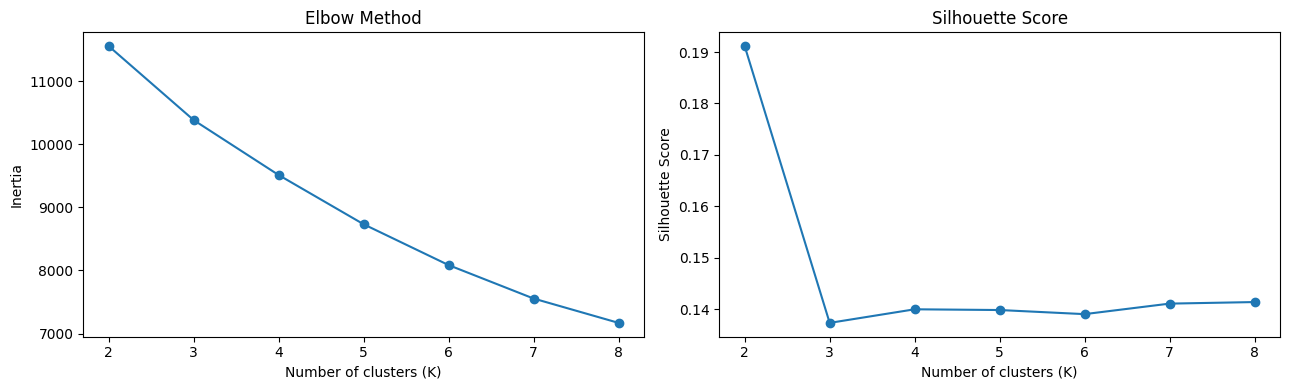

,K,Inertia,Silhouette Score
0,2,11552.9081,0.1912
1,3,10381.1708,0.1373
2,4,9511.3726,0.1400
3,5,8731.9236,0.1398
4,6,8085.1611,0.1390
5,7,7555.5959,0.1411
6,8,7170.0254,0.1414


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

scaler = StandardScaler()
X_customers_scaled = scaler.fit_transform(cluster_features)

k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(X_customers_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_customers_scaled, labels)
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

cluster_evaluation = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

display(cluster_evaluation.round(4))

In [ ]:
best_k = int(
    cluster_evaluation.loc[
        cluster_evaluation["Silhouette Score"].idxmax(), "K"
    ]
)

kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

customer_profiles["cluster"] = kmeans_final.fit_predict(
    X_customers_scaled
)

print("Selected K:", best_k)
print("\nCustomers per cluster:")
display(
    customer_profiles["cluster"]
    .value_counts()
    .sort_index()
    .rename("customer_count")
    .to_frame()
)

print("\nCluster profiles:")
cluster_summary = customer_profiles.groupby("cluster").agg(
    customer_count=("customer_id", "count"),
    total_spend_mean=("total_spend", "mean"),
    avg_transaction_mean=("avg_transaction_amount", "mean"),
    transaction_count_mean=("transaction_count", "mean"),
    avg_location_delta=("avg_location_delta_km", "mean"),
    avg_account_age_days=("account_age_days", "mean")
).round(2)

display(cluster_summary)

customer_profiles.to_csv(
    "p2_customer_segments.csv", index=False
)
cluster_summary.to_csv(
    "p2_customer_cluster_profiles.csv"
)

print("Saved customer segmentation outputs.")

Selected K: 2

Customers per cluster:


,customer_count
cluster,
0,588
1,1401



Cluster profiles:


,customer_count,total_spend_mean,avg_transaction_mean,transaction_count_mean,avg_location_delta,avg_account_age_days
cluster,,,,,,
0,588,10341.89,1691.36,6.78,20.50,1811.88
1,1401,3506.95,843.05,4.29,20.63,1845.75


Saved customer segmentation outputs.


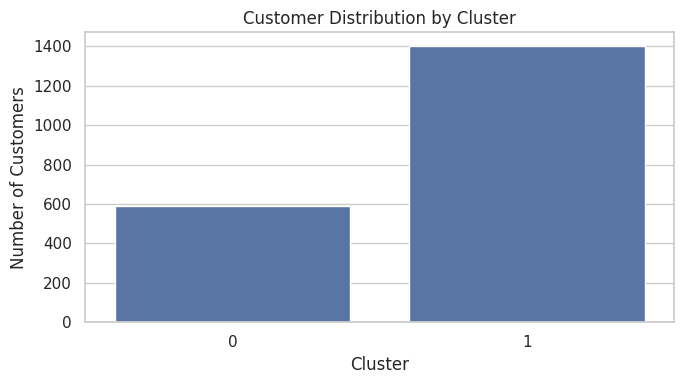

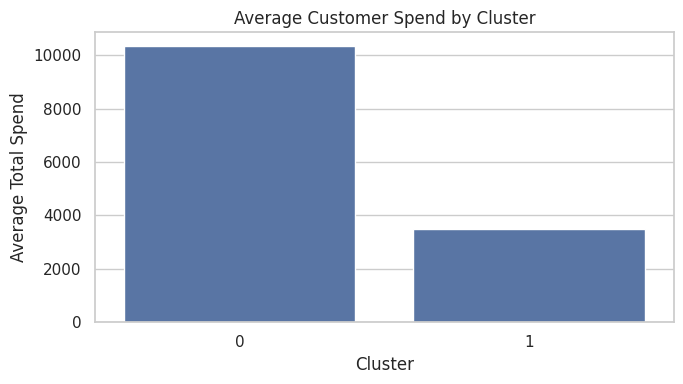

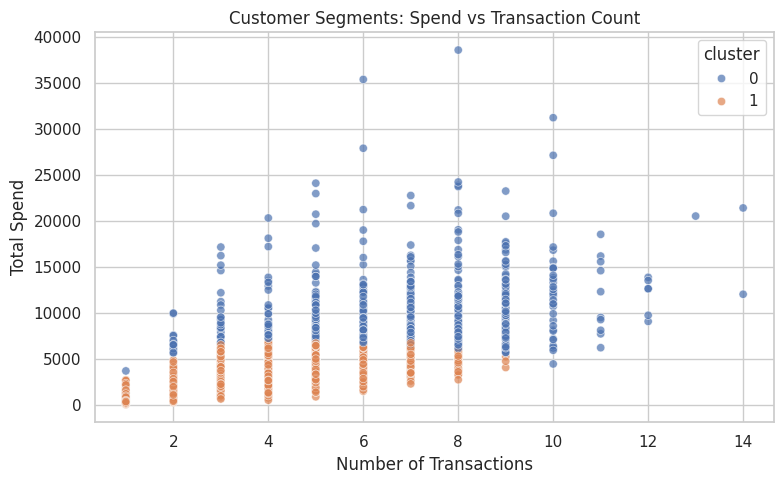

Dashboard charts saved successfully.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Customer counts by cluster
plt.figure(figsize=(7, 4))
sns.countplot(
    data=customer_profiles,
    x="cluster"
)
plt.title("Customer Distribution by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("p2_cluster_customer_counts.png", dpi=150)
plt.show()

# 2. Average total spend by cluster
plt.figure(figsize=(7, 4))
sns.barplot(
    data=customer_profiles,
    x="cluster",
    y="total_spend",
    estimator="mean",
    errorbar=None
)
plt.title("Average Customer Spend by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Total Spend")
plt.tight_layout()
plt.savefig("p2_cluster_average_spend.png", dpi=150)
plt.show()

# 3. Spending vs. transaction frequency
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=customer_profiles,
    x="transaction_count",
    y="total_spend",
    hue="cluster",
    alpha=0.7
)
plt.title("Customer Segments: Spend vs Transaction Count")
plt.xlabel("Number of Transactions")
plt.ylabel("Total Spend")
plt.tight_layout()
plt.savefig("p2_cluster_spend_scatter.png", dpi=150)
plt.show()

print("Dashboard charts saved successfully.")

In [ ]:
import joblib
import json
import os

os.makedirs("p2_models", exist_ok=True)
os.makedirs("p2_results", exist_ok=True)

# Save the fraud classifiers
joblib.dump(
    trained_models["Decision Tree"],
    "p2_models/decision_tree_fraud.joblib"
)
joblib.dump(
    trained_models["Random Forest"],
    "p2_models/random_forest_fraud.joblib"
)

# Save the customer clustering components
joblib.dump(scaler, "p2_models/customer_scaler.joblib")
joblib.dump(kmeans_final, "p2_models/customer_kmeans.joblib")

# Save classification comparison and cluster profiles
comparison.to_csv(
    "p2_results/p2_fraud_classification_comparison.csv"
)
cluster_summary.to_csv(
    "p2_results/p2_customer_cluster_profiles.csv"
)
customer_profiles.to_csv(
    "p2_results/p2_customer_segments.csv",
    index=False
)

report = {
    "project": "P2 - Fintech Transaction Fraud Scoring",
    "dataset_type": "Synthetic demonstration data",
    "transactions": int(len(transactions)),
    "fraud_transactions": int(transactions["is_fraud"].sum()),
    "legitimate_transactions": int((transactions["is_fraud"] == 0).sum()),
    "customer_profiles": int(len(customer_profiles)),
    "selected_k": int(best_k),
    "classification_metrics": {
        name: {
            metric: float(value)
            for metric, value in row.items()
        }
        for name, row in comparison.to_dict(orient="index").items()
    }
}

with open("p2_results/p2_evaluation_report.json", "w") as f:
    json.dump(report, f, indent=2)

print("Models and evaluation artifacts saved.")

Models and evaluation artifacts saved.


In [ ]:
print("Available model names:", list(trained_models.keys()))

Available model names: ['Decision Tree', 'Random Forest']


In [ ]:
import os
import json
import joblib
import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

os.makedirs("p2_models", exist_ok=True)
os.makedirs("p2_results", exist_ok=True)

# Retrain both models
trained_models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in trained_models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    filename = (
        "decision_tree_fraud.joblib"
        if name == "Decision Tree"
        else "random_forest_fraud.joblib"
    )
    joblib.dump(model, f"p2_models/{filename}")

comparison = pd.DataFrame(results).set_index("Model")
comparison.to_csv(
    "p2_results/p2_fraud_classification_comparison.csv"
)

print("Classification models trained and saved.")
display(comparison.round(4))

Classification models trained and saved.


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Decision Tree,0.6500,0.2197,0.4523,0.2958,0.5751
Random Forest,0.7485,0.2486,0.2708,0.2592,0.6161


In [ ]:
import os
import json
import joblib

os.makedirs("p2_models", exist_ok=True)
os.makedirs("p2_results", exist_ok=True)

# Save clustering components
joblib.dump(scaler, "p2_models/customer_scaler.joblib")
joblib.dump(kmeans_final, "p2_models/customer_kmeans.joblib")

# Save customer segmentation results
comparison.to_csv(
    "p2_results/p2_fraud_classification_comparison.csv"
)
cluster_summary.to_csv(
    "p2_results/p2_customer_cluster_profiles.csv"
)
customer_profiles.to_csv(
    "p2_results/p2_customer_segments.csv",
    index=False
)

# Save evaluation report
report = {
    "project": "P2 - Fintech Transaction Fraud Scoring",
    "dataset_type": "Synthetic demonstration data",
    "transactions": int(len(transactions)),
    "fraud_transactions": int(transactions["is_fraud"].sum()),
    "legitimate_transactions": int(
        (transactions["is_fraud"] == 0).sum()
    ),
    "customer_profiles": int(len(customer_profiles)),
    "selected_k": int(best_k),
    "classification_metrics": {
        name: {
            metric: float(value)
            for metric, value in row.items()
        }
        for name, row in comparison.to_dict(orient="index").items()
    }
}

with open("p2_results/p2_evaluation_report.json", "w") as f:
    json.dump(report, f, indent=2)

print("P2 models and reports saved.")
print("\nFiles:")
for root, _, files in os.walk("."):
    for filename in files:
        if filename.startswith("p2_") or filename in [
            "customer_scaler.joblib",
            "customer_kmeans.joblib"
        ]:
            print(os.path.join(root, filename))

P2 models and reports saved.

Files:
./p2_cluster_customer_counts.png
./p2_customer_segments.csv
./p2_fraud_classification_comparison.csv
./p2_cluster_average_spend.png
./p2_cluster_spend_scatter.png
./p2_customer_cluster_profiles.csv
./p2_transactions_synthetic.csv
./p2_results/p2_customer_segments.csv
./p2_results/p2_fraud_classification_comparison.csv
./p2_results/p2_customer_cluster_profiles.csv
./p2_results/p2_evaluation_report.json
./p2_models/customer_scaler.joblib
./p2_models/customer_kmeans.joblib


In [ ]:
import os

print("Fraud models:")
for name in [
    "p2_models/decision_tree_fraud.joblib",
    "p2_models/random_forest_fraud.joblib",
    "p2_models/customer_scaler.joblib",
    "p2_models/customer_kmeans.joblib"
]:
    print(("✅ " if os.path.exists(name) else "❌ ") + name)

Fraud models:
✅ p2_models/decision_tree_fraud.joblib
✅ p2_models/random_forest_fraud.joblib
✅ p2_models/customer_scaler.joblib
✅ p2_models/customer_kmeans.joblib


In [ ]:
from pathlib import Path
import shutil

REPO = Path("/content/ml-genai-enterprise-lab")
P2 = REPO / "P2_Fintech_Fraud_Scoring"

if not REPO.exists():
    raise FileNotFoundError(
        "Existing repository not found. Check the repo path in Colab."
    )

for folder in ["notebook", "models", "results"]:
    (P2 / folder).mkdir(parents=True, exist_ok=True)

# Copy model artifacts
for filename in [
    "decision_tree_fraud.joblib",
    "random_forest_fraud.joblib",
    "customer_scaler.joblib",
    "customer_kmeans.joblib"
]:
    src = Path("p2_models") / filename
    if src.exists():
        shutil.copy2(src, P2 / "models" / filename)
        print("Model copied:", filename)
    else:
        print("Model missing:", filename)

# Copy evaluation outputs
for filename in [
    "p2_transactions_synthetic.csv",
    "p2_fraud_classification_comparison.csv",
    "p2_customer_cluster_profiles.csv",
    "p2_customer_segments.csv",
    "p2_evaluation_report.json",
    "p2_cluster_customer_counts.png",
    "p2_cluster_average_spend.png",
    "p2_cluster_spend_scatter.png"
]:
    candidates = [
        Path(filename),
        Path("p2_results") / filename
    ]
    src = next((p for p in candidates if p.exists()), None)

    if src:
        shutil.copy2(src, P2 / "results" / filename)
        print("Result copied:", filename)
    else:
        print("Result missing:", filename)

print("\nP2 folder:", P2)

Model copied: decision_tree_fraud.joblib
Model copied: random_forest_fraud.joblib
Model copied: customer_scaler.joblib
Model copied: customer_kmeans.joblib
Result copied: p2_transactions_synthetic.csv
Result copied: p2_fraud_classification_comparison.csv
Result copied: p2_customer_cluster_profiles.csv
Result copied: p2_customer_segments.csv
Result copied: p2_evaluation_report.json
Result copied: p2_cluster_customer_counts.png
Result copied: p2_cluster_average_spend.png
Result copied: p2_cluster_spend_scatter.png

P2 folder: /content/ml-genai-enterprise-lab/P2_Fintech_Fraud_Scoring


In [ ]:
import os
import getpass
import subprocess

REPO_URL = (
    "https://github.com/"
    "MarthatiVignesh/ml-genai-enterprise-lab.git"
)
REPO = "/content/ml-genai-enterprise-lab"

if not os.path.exists(REPO):
    token = getpass.getpass("Enter GitHub Personal Access Token: ")

    try:
        # Use the token for this command only; don't print or save it.
        from urllib.parse import quote

        authenticated_url = (
            "https://"
            + quote("MarthatiVignesh", safe="")
            + ":"
            + quote(token, safe="")
            + "@github.com/MarthatiVignesh/ml-genai-enterprise-lab.git"
        )

        subprocess.run(
            ["git", "clone", authenticated_url, REPO],
            check=True
        )
        print("Repository cloned successfully!")

    finally:
        token = None
        authenticated_url = None
else:
    print("Repository already exists:", REPO)

Repository already exists: /content/ml-genai-enterprise-lab


In [ ]:
import os

print("Repository exists:", os.path.isdir(REPO))
print("Repository files:", os.listdir(REPO)[:20])

Repository exists: True
Repository files: ['.git', 'P2_Fintech_Fraud_Scoring', '.gitignore', 'P1_Industrial_IoT_Failure_Prediction']


In [ ]:
from pathlib import Path
import shutil

REPO = Path("/content/ml-genai-enterprise-lab")
P2 = REPO / "P2_Fintech_Fraud_Scoring"

assert REPO.exists(), "Repository not found!"
assert (REPO / ".git").exists(), "Git metadata not found!"

for folder in ["notebook", "models", "results"]:
    (P2 / folder).mkdir(parents=True, exist_ok=True)

# Copy available models
model_files = [
    "decision_tree_fraud.joblib",
    "random_forest_fraud.joblib",
    "customer_scaler.joblib",
    "customer_kmeans.joblib"
]

for filename in model_files:
    source = Path("p2_models") / filename
    if source.exists():
        shutil.copy2(source, P2 / "models" / filename)
        print("Copied model:", filename)
    else:
        print("Not found yet:", filename)

# Copy generated reports, dataset and charts
result_files = [
    "p2_transactions_synthetic.csv",
    "p2_fraud_classification_comparison.csv",
    "p2_customer_cluster_profiles.csv",
    "p2_customer_segments.csv",
    "p2_evaluation_report.json",
    "p2_cluster_customer_counts.png",
    "p2_cluster_average_spend.png",
    "p2_cluster_spend_scatter.png"
]

for filename in result_files:
    candidates = [
        Path(filename),
        Path("p2_results") / filename
    ]
    source = next((p for p in candidates if p.exists()), None)

    if source:
        shutil.copy2(source, P2 / "results" / filename)
        print("Copied result:", filename)
    else:
        print("Not found yet:", filename)

print("\nP2 folder prepared:", P2)

Copied model: decision_tree_fraud.joblib
Copied model: random_forest_fraud.joblib
Copied model: customer_scaler.joblib
Copied model: customer_kmeans.joblib
Copied result: p2_transactions_synthetic.csv
Copied result: p2_fraud_classification_comparison.csv
Copied result: p2_customer_cluster_profiles.csv
Copied result: p2_customer_segments.csv
Copied result: p2_evaluation_report.json
Copied result: p2_cluster_customer_counts.png
Copied result: p2_cluster_average_spend.png
Copied result: p2_cluster_spend_scatter.png

P2 folder prepared: /content/ml-genai-enterprise-lab/P2_Fintech_Fraud_Scoring


In [ ]:
readme = """# P2 — Fintech Transaction Fraud Scoring & Customer Segmentation

## Objective
Build a machine-learning prototype for transaction fraud classification
and customer spending segmentation.

## Models
- Decision Tree classifier
- Random Forest classifier
- K-Means clustering

## Evaluation
- Classification comparison: `results/p2_fraud_classification_comparison.csv`
- Customer cluster profiles: `results/p2_customer_cluster_profiles.csv`
- Evaluation report: `results/p2_evaluation_report.json`

## Data limitation
This project uses synthetic demonstration data with artificially generated
fraud labels. Metrics must not be interpreted as validated real-world
financial fraud detection performance.

## Notebook
Run `notebook/P2_Fintech_Fraud_Scoring.ipynb` in Google Colab.
"""

(P2 / "README.md").write_text(readme, encoding="utf-8")
print("README created.")

README created.


In [ ]:
import subprocess

REPO = "/content/ml-genai-enterprise-lab"

subprocess.run(
    ["git", "add", "P2_Fintech_Fraud_Scoring"],
    cwd=REPO,
    check=True
)

subprocess.run(
    ["git", "status", "--short"],
    cwd=REPO,
    check=True
)

CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [ ]:
import os
import subprocess
import getpass
import base64

REPO = "/content/ml-genai-enterprise-lab"
USERNAME = "MarthatiVignesh"
REPO_URL = (
    "https://github.com/"
    "MarthatiVignesh/ml-genai-enterprise-lab.git"
)

if not os.path.isdir(REPO):
    token = getpass.getpass("GitHub Personal Access Token: ")
    auth = base64.b64encode(
        f"{USERNAME}:{token}".encode()
    ).decode()

    env = os.environ.copy()
    env["GIT_CONFIG_COUNT"] = "1"
    env["GIT_CONFIG_KEY_0"] = "http.https://github.com/.extraheader"
    env["GIT_CONFIG_VALUE_0"] = "AUTHORIZATION: basic " + auth

    try:
        subprocess.run(
            ["git", "clone", REPO_URL, REPO],
            env=env,
            check=True
        )
        print("Repository cloned successfully!")
    finally:
        token = auth = env = None
else:
    print("Repository already exists.")

Repository already exists.


In [ ]:
import os

print("Repository exists:", os.path.isdir(REPO))
if os.path.isdir(REPO):
    print("Git metadata exists:", os.path.isdir(os.path.join(REPO, ".git")))
    print("Files:", os.listdir(REPO))

Repository exists: True
Git metadata exists: True
Files: ['.git', 'P2_Fintech_Fraud_Scoring', '.gitignore', 'P1_Industrial_IoT_Failure_Prediction']


In [ ]:
for path in [
    "/content/p2_models",
    "/content/p2_results",
    "/content/p2_transactions_synthetic.csv",
    "/content/p2_customer_segments.csv"
]:
    print(("✅ " if os.path.exists(path) else "❌ ") + path)

✅ /content/p2_models
✅ /content/p2_results
✅ /content/p2_transactions_synthetic.csv
✅ /content/p2_customer_segments.csv


In [ ]:
import os

paths = [
    "/content/p2_models",
    "/content/p2_results",
    "/content/p2_transactions_synthetic.csv",
    "/content/p2_customer_segments.csv",
]

for path in paths:
    print(f"{'FOUND' if os.path.exists(path) else 'MISSING'}: {path}")

FOUND: /content/p2_models
FOUND: /content/p2_results
FOUND: /content/p2_transactions_synthetic.csv
FOUND: /content/p2_customer_segments.csv


In [32]:
import os

print("=== CHARTS ===")
charts = [
    "p2_cluster_customer_counts.png",
    "p2_cluster_average_spend.png",
    "p2_cluster_spend_scatter.png",
]

for chart in charts:
    print(("FOUND: " if os.path.exists(chart) else "MISSING: ") + chart)

print("\n=== REQUIRED DATA ===")
required = [
    "p2_transactions_synthetic.csv",
    "p2_customer_segments.csv",
    "p2_customer_cluster_profiles.csv",
    "p2_fraud_classification_comparison.csv",
]

for file in required:
    print(("FOUND: " if os.path.exists(file) else "MISSING: ") + file)

=== CHARTS ===
FOUND: p2_cluster_customer_counts.png
FOUND: p2_cluster_average_spend.png
FOUND: p2_cluster_spend_scatter.png

=== REQUIRED DATA ===
FOUND: p2_transactions_synthetic.csv
FOUND: p2_customer_segments.csv
FOUND: p2_customer_cluster_profiles.csv
FOUND: p2_fraud_classification_comparison.csv


In [33]:
import os

repo = "/content/ml-genai-enterprise-lab"

print("Repository exists:", os.path.isdir(repo))
if os.path.isdir(repo):
    print("Repository folders:", os.listdir(repo))

Repository exists: True
Repository folders: ['.git', 'P2_Fintech_Fraud_Scoring', '.gitignore', 'P1_Industrial_IoT_Failure_Prediction']


In [34]:
import os
import shutil

repo = "/content/ml-genai-enterprise-lab"
p2 = os.path.join(repo, "P2_Fintech_Fraud_Scoring")

os.makedirs(os.path.join(p2, "notebook"), exist_ok=True)
os.makedirs(os.path.join(p2, "models"), exist_ok=True)
os.makedirs(os.path.join(p2, "results"), exist_ok=True)

# Copy the current Colab notebook if available
notebook_name = "P2_Fintech_Fraud_Scoring.ipynb"
notebook_source = os.path.join("/content", notebook_name)

if os.path.exists(notebook_source):
    shutil.copy2(
        notebook_source,
        os.path.join(p2, "notebook", notebook_name)
    )
    print("Notebook copied.")
else:
    print("Notebook file not found in /content; save/download it from Colab.")

# Copy models
for name in os.listdir("/content/p2_models"):
    src = os.path.join("/content/p2_models", name)
    if os.path.isfile(src):
        shutil.copy2(src, os.path.join(p2, "models", name))

# Copy results and data
files = [
    "p2_transactions_synthetic.csv",
    "p2_customer_segments.csv",
    "p2_customer_cluster_profiles.csv",
    "p2_fraud_classification_comparison.csv",
    "p2_cluster_customer_counts.png",
    "p2_cluster_average_spend.png",
    "p2_cluster_spend_scatter.png",
]

for name in files:
    src = os.path.join("/content", name)
    if os.path.isfile(src):
        shutil.copy2(src, os.path.join(p2, "results", name))

# Copy evaluation report if present in p2_results
report = "/content/p2_results/p2_evaluation_report.json"
if os.path.isfile(report):
    shutil.copy2(report, os.path.join(p2, "results", "p2_evaluation_report.json"))

print("\nP2 files copied. Contents:")
for root, dirs, filenames in os.walk(p2):
    for name in filenames:
        print(os.path.relpath(os.path.join(root, name), repo))

Notebook file not found in /content; save/download it from Colab.

P2 files copied. Contents:
P2_Fintech_Fraud_Scoring/README.md
P2_Fintech_Fraud_Scoring/results/p2_cluster_customer_counts.png
P2_Fintech_Fraud_Scoring/results/p2_customer_segments.csv
P2_Fintech_Fraud_Scoring/results/p2_fraud_classification_comparison.csv
P2_Fintech_Fraud_Scoring/results/p2_cluster_average_spend.png
P2_Fintech_Fraud_Scoring/results/p2_cluster_spend_scatter.png
P2_Fintech_Fraud_Scoring/results/p2_customer_cluster_profiles.csv
P2_Fintech_Fraud_Scoring/results/p2_evaluation_report.json
P2_Fintech_Fraud_Scoring/results/p2_transactions_synthetic.csv
P2_Fintech_Fraud_Scoring/models/customer_scaler.joblib
P2_Fintech_Fraud_Scoring/models/random_forest_fraud.joblib
P2_Fintech_Fraud_Scoring/models/decision_tree_fraud.joblib
P2_Fintech_Fraud_Scoring/models/customer_kmeans.joblib
